In [1]:
%load_ext autoreload
%autoreload 2

import sys
import torch
from pathlib import Path
import urllib.request
import matplotlib.pyplot as plt

# Aponta para a pasta raiz (ajuste conforme a estrutura do seu projeto)
sys.path.append(str(Path.cwd().parent / 'Codigo'))
sys.path.append(str(Path.cwd()))

from bpe import BPETokenizer
from dataset import create_dataloader_v1
from model import GPTModel
from treinamento import train_model

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Usando dispositivo: {device}')

Usando dispositivo: cpu


In [2]:
# 1. Preparação dos Dados
url = 'https://raw.githubusercontent.com/rasbt/LLMs-from-scratch/main/ch02/01_main-chapter-code/the-verdict.txt'
urllib.request.urlretrieve(url, 'the-verdict.txt')

with open('the-verdict.txt', 'r', encoding='utf-8') as f:
    texto = f.read()

# Divisão Treino e Validação
split_idx = int(0.9 * len(texto))
train_data = texto[:split_idx]
val_data = texto[split_idx:]

# Configurações dos Lotes
BATCH_SIZE = 4
CONTEXT_LENGTH = 256

bpe = BPETokenizer('gpt2')
train_loader = create_dataloader_v1(train_data, batch_size=BATCH_SIZE, max_length=CONTEXT_LENGTH, stride=CONTEXT_LENGTH, drop_last=True)
val_loader = create_dataloader_v1(val_data, batch_size=BATCH_SIZE, max_length=CONTEXT_LENGTH, stride=CONTEXT_LENGTH, drop_last=False)

print('DataLoaders criados com sucesso!')

DataLoaders criados com sucesso!


In [3]:
# 2. Configuração do Modelo e Hiperparâmetros
GPT_CONFIG = {
    'vocab_size': bpe.vocab_size, 'context_length': CONTEXT_LENGTH, 'emb_dim': 768,
    'n_heads': 12, 'n_layers': 12, 'drop_rate': 0.1, 'qkv_bias': False
}

torch.manual_seed(123)
model = GPTModel(GPT_CONFIG).to(device)

# Parâmetros de Treinamento
NUM_EPOCHS = 15
LEARNING_RATE = 4e-4
WEIGHT_DECAY = 0.1
EVAL_FREQ = 5
EVAL_ITER = 5

# Otimizador com Weight Decay (AdamW)
optimizer = torch.optim.AdamW(model.parameters(), lr=LEARNING_RATE, weight_decay=WEIGHT_DECAY)

print(f'Modelo instanciado. Otimizador: {optimizer.__class__.__name__}')

Modelo instanciado. Otimizador: AdamW


In [4]:
# 3. Loop de Treinamento
print(f'Iniciando treino com Batch Size {BATCH_SIZE}, {NUM_EPOCHS} Épocas e LR {LEARNING_RATE}...')

train_losses, val_losses, tokens_seen = train_model(
    model=model, 
    train_loader=train_loader, 
    val_loader=val_loader, 
    optimizer=optimizer, 
    device=device, 
    num_epochs=NUM_EPOCHS, 
    eval_freq=EVAL_FREQ,
    eval_iter=EVAL_ITER
)

print('Treinamento finalizado.')

Iniciando treino com Batch Size 4, 15 Épocas e LR 0.0004...
Época 01 | Step 0000 | Train Loss: 9.6521 | Val Loss: 9.8338
Época 02 | Step 0005 | Train Loss: 7.7807 | Val Loss: 8.0440
Época 03 | Step 0010 | Train Loss: 6.3036 | Val Loss: 6.8715
Época 04 | Step 0015 | Train Loss: 5.5487 | Val Loss: 6.4722
Época 06 | Step 0020 | Train Loss: 4.8565 | Val Loss: 6.4073
Época 07 | Step 0025 | Train Loss: 4.0574 | Val Loss: 6.2037
Época 08 | Step 0030 | Train Loss: 3.3463 | Val Loss: 6.1642
Época 09 | Step 0035 | Train Loss: 2.6969 | Val Loss: 6.1605
Época 11 | Step 0040 | Train Loss: 2.1490 | Val Loss: 6.1743
Época 12 | Step 0045 | Train Loss: 1.6108 | Val Loss: 6.2230
Época 13 | Step 0050 | Train Loss: 1.1314 | Val Loss: 6.2796
Época 14 | Step 0055 | Train Loss: 0.7481 | Val Loss: 6.3351
Treinamento finalizado.


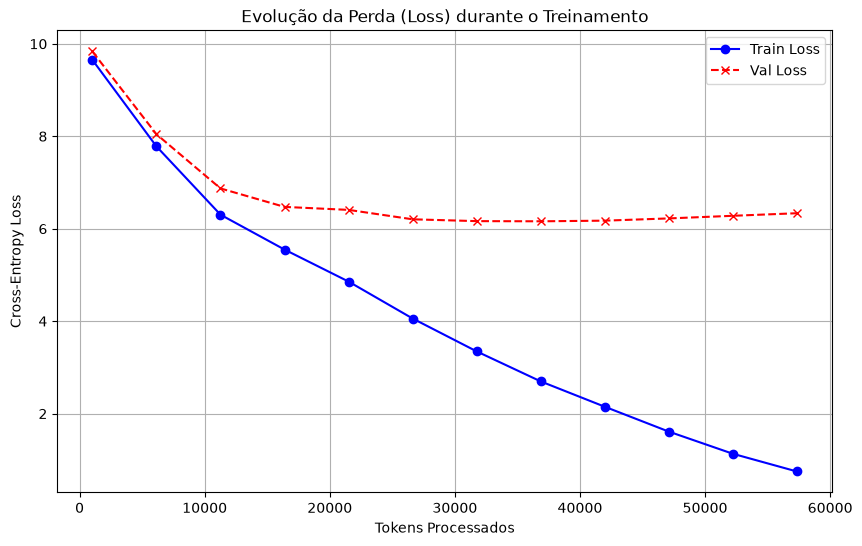

In [5]:
# 4. Acompanhamento Gráfico das Perdas
plt.figure(figsize=(10, 6))
plt.plot(tokens_seen, train_losses, label='Train Loss', marker='o', color='blue')
plt.plot(tokens_seen, val_losses, label='Val Loss', marker='x', color='red', linestyle='--')
plt.xlabel('Tokens Processados')
plt.ylabel('Cross-Entropy Loss')
plt.title('Evolução da Perda (Loss) durante o Treinamento')
plt.legend()
plt.grid(True)
plt.show()